## YOLO V1

- YOLOv1 is CNN based Deep learning model which pioneered series of Object Detection models
- Its a single-stage object detection model (i.e), unlike its predecessors, it uses an end-to-end model to predict bounding boxes in image
- It views `Object Detection as direct regression problem, using novel MSE loss function to directly predict the class and location of objects`

#### Cons
- Struggles to detect small objects
- Has more `Localisation errors` compared to contemporary Fast RCNN

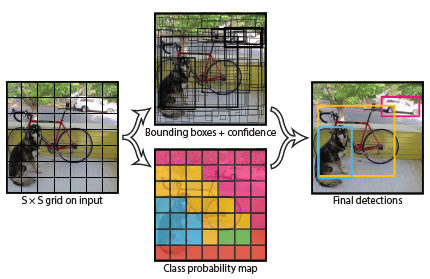

## Library imports

In [1]:
# basic imports
import os
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

# DL library imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import OneCycleLR

# Add scripts folder to sys.path
import sys
SCRIPTS_DIR = '/kaggle/input/objdetectionscripts/scripts'
sys.path.append(SCRIPTS_DIR)

# custom class imports
from dataset.vocDataset import vocDataset, transformComponse
from lossfns.yoloV1Loss import yoloV1Loss
from models.yoloV1 import yoloV1

# dataset constants
from dataset.vocDataset import STD_IMG_TRANSFORM, STD_INVERSE_TRANSFORM, VOC_COLOR_MAP

# helper functions import
from metrics.iou import intersectionOverUnion
from metrics.nms import nonMaximalSuppression
from metrics.meanAveragePrecision import meanAveragePrecision
from utils import cellBoxesToBoxes, getBoundingBoxes
from utils import plotDatasetSamples, plotLrFinderResults, lrFinder
from utils import train_model, visualizeModelPredictions, plotTrainingResults

## File Constants

In [2]:
# data related constants
DATA_DIR = "/kaggle/input/pascalvoc-yolo"
IMG_DIR =  os.path.join(DATA_DIR, *["images"])
LABEL_DIR =  os.path.join(DATA_DIR, *["labels"])

PIN_MEMORY = True
LOAD_MODEL = False
NUM_WORKERS = 2
TRAIN_BATCH_SIZE = 16
TEST_BATCH_SIZE = 16
LOAD_MODEL_FILE = "overfit.pth.tar"

# YOLO v1 constants
S = 7    # no of grid cells
B = 2    # no of bounding box predictions per grid cell
C = 20   # no of classes
NUM_CLASSES = C

## Load Dataset

In [3]:
# data augumentation
preprocess = transformComponse(STD_IMG_TRANSFORM)

# Datasets and dataloaders
trainDataset = vocDataset(os.path.join(DATA_DIR, *["train.csv"]),
              imgDir=IMG_DIR, labelsDir=LABEL_DIR, S=S, B=B, C=C, transform=preprocess)
trainLoader = DataLoader(dataset=trainDataset, batch_size=TRAIN_BATCH_SIZE,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, shuffle=True, drop_last=True)

testDataset = vocDataset(os.path.join(DATA_DIR, *["test.csv"]),
              imgDir=IMG_DIR, labelsDir=LABEL_DIR, S=S, B=B, C=C, transform=preprocess)
testLoader = DataLoader(dataset=testDataset, batch_size=TEST_BATCH_SIZE,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, shuffle=True, drop_last=True)

Plot sample images from dataset

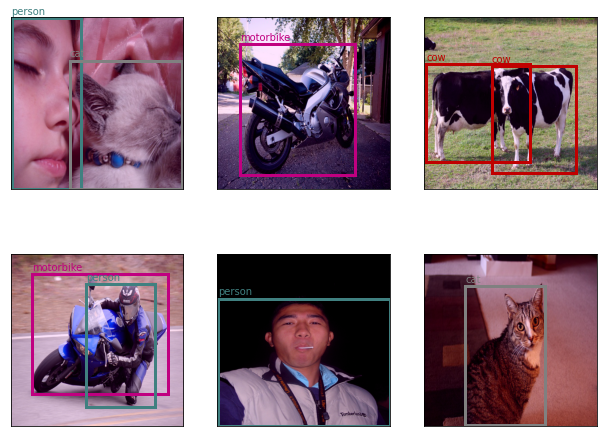

In [4]:
plotDatasetSamples(trainDataset, 6)

## Model

**Model Architecture**

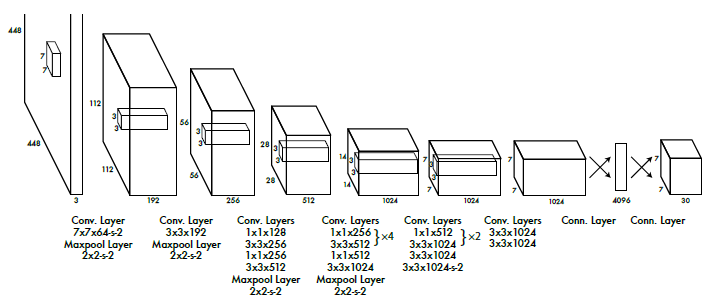

In [5]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu") 

# MODEL HYPERPARAMETERS
MAX_LR = 1e-5
N_EPOCHS = 50
MODEL_NAME = 'yolov1_test'

# create model, optimizer, lr_scheduler and pass to training function
criterion = yoloV1Loss(S=S, B=B, C=C)
# criterion = YoloLoss(S=S, B=B, C=C)

model = yoloV1(splitSize=S, numBoxes=B, numClasses=NUM_CLASSES).to(device)
optimizer = optim.Adam(model.parameters(), lr=MAX_LR)
scheduler = OneCycleLR(optimizer, max_lr= MAX_LR, epochs = N_EPOCHS,steps_per_epoch = len(trainLoader), 
                       pct_start=0.3, div_factor=10, anneal_strategy='cos')

## Lr finder

In [6]:
# lrFinderResults = lrFinder(model, optimizer, trainLoader, criterion, device, numBatches = 100)
# plotLrFinderResults(lrFinderResults)

## Train function

100%|██████████| 1034/1034 [06:26<00:00,  2.68it/s]


Epoch: 1,trainLoss:486.46501,trainMetric(mAP): 0.00,predBoxes = 32302,targetBoxes:37113


100%|██████████| 1034/1034 [06:07<00:00,  2.81it/s]


Epoch: 2,trainLoss:273.77554,trainMetric(mAP): 0.00,predBoxes = 23253,targetBoxes:37108


100%|██████████| 1034/1034 [06:07<00:00,  2.82it/s]


Epoch: 3,trainLoss:202.87222,trainMetric(mAP): 0.00,predBoxes = 19325,targetBoxes:37116


... (90 outputs left out)

100%|██████████| 1034/1034 [06:08<00:00,  2.80it/s]


Epoch: 49,trainLoss:11.39963,trainMetric(mAP): 0.95,predBoxes = 37267,targetBoxes:37118


100%|██████████| 1034/1034 [06:08<00:00,  2.81it/s]


Epoch: 50,trainLoss:11.33583,trainMetric(mAP): 0.95,predBoxes = 37268,targetBoxes:37120


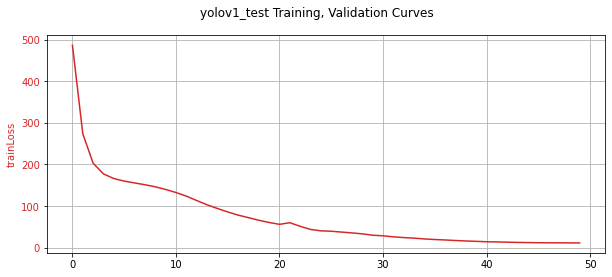

In [7]:
# initialize placeholders for running values
results = []    
valData = {}
trainData = {}
min_val_loss = np.Inf
metricName = 'mAP'

for epoch in range(N_EPOCHS):
    trainData = train_model(model, trainLoader, criterion, optimizer, scheduler, num_classes=NUM_CLASSES, device=device, metric_class=None)    
#     valData = evaluate_model(model, testLoader, criterion, num_classes=NUM_CLASSES, device=device, metric_class=None)

    predBoxes, targetBoxes = getBoundingBoxes(trainLoader, model, iouThreshold=0.5, threshold=0.4, device=device)
    meanAvgPrec = meanAveragePrecision(predBoxes, targetBoxes, iouThreshold=0.5, boxFormat="midpoint")

    print(f"Epoch: {epoch+1},trainLoss:{trainData.get('mean_loss', np.inf):6.5f},trainMetric({metricName}):{meanAvgPrec: 3.2f},predBoxes = {len(predBoxes)},targetBoxes:{len(targetBoxes)}")    
#     print(f"Epoch: {epoch+1}, \
#             trainLoss:{trainData.get('mean_loss', np.inf):6.5f}, \
#             validationLoss:{valData.get('mean_loss', np.inf):6.5f}, \
#             trainMetric({metricName}):{trainData.get('metric', 0.0): 4.2f}, \
#             validationMetric({metricName}):{valData.get('metric', 0.0): 4.2f}")
        
    # store results
    results.append({'epoch': epoch, 
                    'trainLoss': trainData.get('mean_loss', np.inf),
                    'validationLoss': valData.get('mean_loss', np.inf), 
                    f"validationMetric({metricName})": valData.get('metric', 0.0)})
        
#     # if validation loss has decreased, save model and reset variable
#     if valData.get('mean_loss', np.inf) <= min_val_loss:
#         min_val_loss = valData.get('mean_loss', np.inf)
#         torch.save(model.state_dict(), f"{output_path}/{model_name}.pt")
#         # torch.jit.save(torch.jit.script(model), f"{output_path}/{model_name}.pt")


# plot results
results = pd.DataFrame(results)
plotTrainingResults(results, MODEL_NAME)

In [8]:
# save model weights
torch.save(model.state_dict(), f"{MODEL_NAME}.pt")

## Visualize model predictions

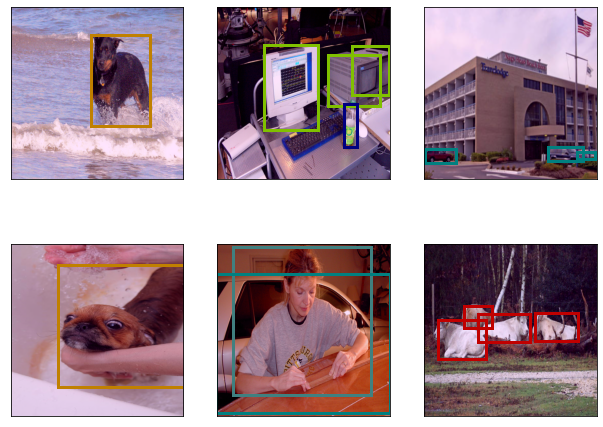

In [9]:
visualizeModelPredictions(model, trainDataset, device, 6)